Objectives:

- link between relative frequencies and probabilities

- conditional probabilities and the law of total probability

Data file: nlsy97_transitions.parquet

on Moodle: Employment Status and College Enrollment Transitions



#### Loading the packages

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import numpy as np


#### Loading the data

In [2]:
ROOT = 'c:/Users/PC_DS_ECON_5/Desktop/data-analytics-python-example'
DATA = ROOT + '/data'


In [3]:
df = pd.read_parquet(DATA + 
                     '/nlsy97_transitions.parquet')

Structure of the dataset is very similar to nlsy97_emp_hed.parquet

Only differences: 

 - two new variables

 - if the two new variables are missing, then the observation was removed

Recall that the unit of observation was:

`person_id` X `year_month`


In [4]:
# new variables are never missing
df[['emp_category_next', 'college_status_next']].isna().any().sum()

np.int64(0)

In [5]:
# unit of observation is individual X month
df[['person_id', 'year_month']].value_counts().value_counts()

count
1    2111795
Name: count, dtype: int64

Let us work with observations from a single month

Let us select a month randomly

`numpy` package has a "random number generator" 

 - pseudo-random number generator
 - one specifies a particular number (seed number)
 - every time one runs the same code, the same "random" values are selected
 - when specifying the seed number, we do not know what random draws will occur
 - but they are the same if code is run from the beginning

Creating a random number generator object with "seed" value

rng abbreviation for random number generator

Function: np.random.default_rng()



In [6]:
rng = np.random.default_rng(seed=8763534)

Objective: let us select a month randomly 

using our random number generator and `choice()` function attached to it 

First:
list of months (each only once), and not the entire column of the dataset
such that every month has the same probability of being drawn randomly

In [7]:
# running the code from the beginning 
# (from the specification of the seed value)
# will always produce the same result
rng = np.random.default_rng(seed=8763534)
chosen_month = rng.choice(
    # set of values from which to choose "randomly"
    a=df['year_month'].drop_duplicates()
)
chosen_month

Period('2020-08', 'M')

Advantage: reproduceable

Point to keep in mind:
seed value can be / is chosen arbitrarily
I can choose the seed value that produces the result that I want.

Let us subset the dataset, let us treat the observations from the chosen month as a *statistical population*. Statistical population, because the objective then is to draw random samples from this statistical population.

In [8]:
# keeping only observations from the chosen month
df1 = (
    df
        .loc[df['year_month'].eq(chosen_month),:]
        .reset_index(drop=True)
        .copy()
)

In [9]:
df1['year_month'].drop_duplicates()

0    2020-08
Name: year_month, dtype: period[M]

Let us create a variable:

a dummy variable

non-participant =
1 if the person is non-participant (`emp_category=non-participant`)
0 otherwise

binary variable, with two values 1 and 0 (answer to a Yes/No question)

a simple way to translate qualitative information into quantitative information


In [ ]:
# numpy.where(condition, value if true, value if false)
# conditional assignment of values to variables
# dummy variable non-participant
# 
df1['non-participant'] = np.where(
    # condition ---> column of Trues and Falses
    df1['emp_category'].eq('non-participant'),
    # value if condition holds / True
    1,
    # value if condition does not hold / False
    0    
)

`df1` is the statistical population (thought experiment)

for this population, let us compute 
 - the relative frequency/share/proportion of being non-participant 

number of individuals with non-participant=1
divided by
number of individuals alltogether


In [12]:
# population relative frequency of non-participants
# population share of individuals such that 
# the dummy variable non-participant is equal to 1

# very explicit way of proceeding: 
# to insist on the fact that it is a relative frequency / share / proportion
population_rel_freq = (
    # number of individuals who are non-participant
    df1['non-participant'].eq(1).sum()
    # divided by
    /
    # total number of individuals
    df1.shape[0]
)

In [13]:
population_rel_freq

np.float64(0.16533864541832669)

The objective from now on will be to draw random samples from this population and compare the relative frequencies of non-participants with the population relative frequency.

Illustrate a version of the law of large numbers.
What happens as the sample size increases?

Recall:

dataframe `df1` is our statistical population

for the sake of the thought experiment

objective: drawing random samples from this artificial statistical population

In [ ]:
# defining a new random number generator
# so that every time this cell is run
# the same sample will be chosen
rng = np.random.default_rng(seed=567853)
# draw random sample(s) from the population
individual_drawn = rng.choice(
    # the statistical population / the object from which the elements are drawn
    # underlying set of values: individual identifiers
    a=df1['person_id']
)
print('individual identifier:', individual_drawn)
print('value of the variable non-participant for this individual:',
      (
        df1
            .loc[df1['person_id'].eq(individual_drawn),
                 'non-participant']
            .iloc[0]
      ))


individual identifier: 2045
value of the variable non-participant for this individual: 0


In [21]:
rng = np.random.default_rng(seed=97634)
# draw random sample(s) from the population
individuals_drawn = rng.choice(
    # the statistical population / the object from which the elements are drawn
    # underlying set of values: individual identifiers
    a=df1['person_id'],
    # sample size
    size=10,
    # making sure that individuals are drawn at most once
    # without replacement
    replace=False
)

sample = (
    (
        df1
            # is the identifier in the set of values?
            .loc[df1['person_id'].isin(individuals_drawn),
            # select the columns: identifier and value of the variable non-participant
                    ['person_id', 'non-participant']]
    )
)


# printing the sample
print(sample)

# sample relative frequency of non-participant==1
sample_rel_freq = (
    # count the number of observations for which the condition holds
    sample['non-participant'].eq(1).sum()
    # divided by
    /
    # the sample size
    sample.shape[0]
)
print('sample relative frequency:', sample_rel_freq)

      person_id  non-participant
811        1063                0
1474       1941                0
2046       2696                0
2305       3031                0
3165       4154                0
3927       5142                0
4641       6022                0
4818       6248                0
5700       7382                1
6156       7946                0
sample relative frequency: 0.1


The sample above is relatively small

What happens when increasing the sample size

Let us increase the sample size up to 100000
Let us carry out 100000 random draws from our artificial population (this time with replacement, otherwise we would run out of individuals)

Another reason for random sampling *with replacement*: The theory generally applies to / assumes random sampling with replacement. (The difference is usually small/negligible for examples that we encounter here.) 

The way to think about this exercise:
 - the sample size is progressively increased to 100000
 - new draws are being progressively added to the sample 
But we can still carry out all the 100000 draws at once:
 - these draws are independent
 - every time a draw is carried out from the same population
 - regardless of the previous draw

In [35]:
rng = np.random.default_rng(seed=329484)
individuals_drawn = rng.choice(
    # statistical population
    a=df1['person_id'],
    # (maximal) sample size
    size=100000,
    # this time with replacement (defaul)
    # there will be individuals who are drawn more than once
    replace=True
)
# sample data
sample = (
    df1[['person_id', 'non-participant']]
        # setting the identifier as the index
        .set_index('person_id')
        # it will automatically recognise that I am selecting based on the index values
        # rows will occur as many times as dictated by the set of indices individuals_drawn
        # objective: allow for an individual occurring multiple times 
        .loc[individuals_drawn]
        # make sure that person_id is column and not the index of the dataframe
        .reset_index()
        .copy()
)
# there are person identifiers that occur multiple times (here this is intended behaviour)
sample.person_id.value_counts().value_counts().head(5) # about 700 individuals occur about 14 times
 

count
13    754
14    699
15    686
16    673
12    651
Name: count, dtype: Int64

Intended interpretation:

progressively increasing the sample size, adding new random draws to the sample

to see how the sample relative frequency evolves as new random draws are being added

at each row: consider the sample being all observations up to the particular row
 - sample size is the number of rows up to that particular row
 - sample relative frequency is the relative frequency with respect to all rows up to the particular row

In [36]:
sample['size'] = (
    sample.index + 1
)
sample['rel_freq_nonparticipant'] = (
    # number of observations up to that row with non-participant==1
    # take the sum of non-participants 
    # (because it is 1 if True and 0 if not / nice property of dummy variable)
    # summing the values of non-participant up to the particular row
    # cumsum() function
    sample['non-participant'].cumsum()
    # divided by (usually it is interpreted in such a case as row-by-row division)
    # division takes place within each row
    /
    # sample size
    sample['size']
)

sample

,person_id,non-participant,size,rel_freq_nonparticipant
0,7201,0,1,0.000000
1,4633,0,2,0.000000
2,6933,0,3,0.000000
3,5096,0,4,0.000000
4,5156,0,5,0.000000
...,...,...,...,...
99995,699,0,99996,0.164587
99996,8569,0,99997,0.164585
99997,611,0,99998,0.164583
99998,1137,0,99999,0.164582


Objective:

plotting the relative frequency of non-participants against the sample size

how the sample relative frequency evolves as the sample size increases

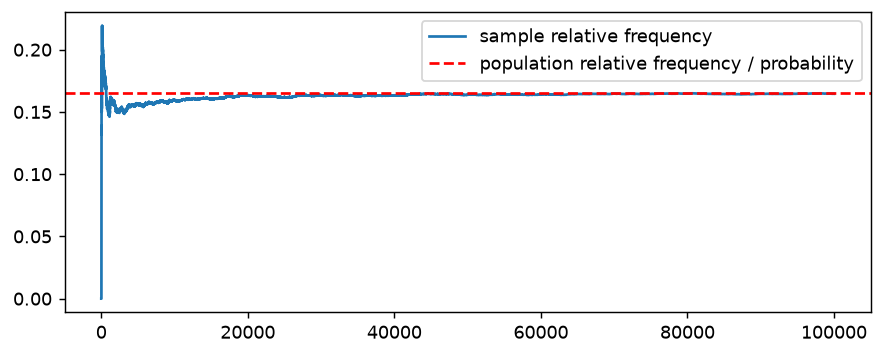

In [45]:
# matplotlib
fig, ax = plt.subplots(figsize=(8,3), dpi=130)
# on the horizontal axis: sample size
# on the vertical axis: the corresponding relative frequency
ax.plot(
    sample['size'], 
    sample['rel_freq_nonparticipant'], 
    label='sample relative frequency'
    )
ax.axhline(y=population_rel_freq, 
           color='red', 
           linestyle='--', 
           label='population relative frequency / probability')
ax.legend()

This provides an illustration for a version of the law of large numbers.

Motivation: probability and relative frequency / share / proportion tightly related
Sometimes they can be used interchangeably

probability is meant for the statistical population
relative frequency is meant for the sample / data



### Conditional probabilities and the law of total probability

Transition probabilities between labor market status categories

Typical example:
Probability of becoming employed next month if unemployed this month
$$
\mathbb{P}[ employed(t+1) | unemployed(t) ]
$$


Let us first create a coarser definition of employment status:

- instead of five categories, let us define three